# 时间序列切分  +  训练 + MLflow

In [ ]:
#1.  依赖安装
-  uv add "pyarrow>=14,<20" "mlflow>=2.9"
- uv add lightgbm  scikit-learn

In [ ]:
# 2. 写 src/training/train.py，进行模型训练
- 详见 quant-mlops-project/src/training/train.py
- 该脚本的作用：
通过划分5个不同时间段的 训练、验证、测试 数据集，来训练模型，查找IC值、rmse 和 

In [ ]:
# 3. 打开mlfow，并声明数据文件
mlflow ui --backend-store-uri sqlite:///mlflow.db

In [1]:
# 4. 查看特征数据情况
import pandas as pd
df = pd.read_parquet('/home/mlops/quant-mlops-project/data/features/features.parquet')

In [2]:
df.ticker.unique()

<ArrowStringArray>
[ 'AAPL',  'ABBV',   'ABT',   'ACN',  'ADBE',   'ADI',   'ADP',  'AMAT',
   'AMD',  'AMGN',  'AMZN',  'AVGO',   'AXP',    'BA',   'BAC',  'BKNG',
   'BLK',   'BMY', 'BRK-B',   'BSX',     'C',   'CAT',    'CB',    'CI',
   'CME',   'COP',  'COST',   'CRM',  'CSCO',   'CVS',   'CVX',    'DE',
   'DHR',   'DUK',   'ELV',  'EQIX',  'FISV',    'GE',  'GILD', 'GOOGL',
    'GS',    'HD',   'HON',   'IBM',   'ICE',  'INTC',  'INTU',  'ISRG',
   'JNJ',   'JPM',  'KLAC',    'KO',   'LIN',   'LLY',   'LMT',   'LOW',
    'MA',   'MCD',  'MDLZ',   'MDT',  'META',    'MO',   'MRK',  'MRSH',
  'MSFT',    'MU',   'NEE',  'NFLX',   'NOW',  'NVDA',   'PEP',   'PFE',
    'PG',   'PGR',   'PLD',    'PM',  'PYPL',  'QCOM',  'REGN',   'RTX',
  'SBUX',  'SCHW',    'SO',  'SPGI',   'SYK',     'T',   'TJX',   'TMO',
  'TSLA',   'TXN',  'UBER',   'UNH',   'UNP',     'V',  'VRTX',    'VZ',
   'WFC',   'WMT',   'XOM',   'ZTS']
Length: 100, dtype: str

In [3]:
df.describe()


,date,open,high,low,close,volume,ret_1d,ret_5d,ret_20d,vol_5d,vol_20d,vol_ma20,vol_ratio,high_20,low_20,price_pos,ma_5,ma_20,ma_ratio,label
count,291878,291878.000000,291878.000000,291878.000000,291878.000000,2.918780e+05,291878.000000,291878.000000,291878.000000,291878.000000,291878.000000,2.918780e+05,291878.000000,291878.000000,291878.000000,2.918780e+05,291878.000000,291878.000000,291878.000000,291878.000000
mean,2020-12-02 11:09:40.656000,153.050579,154.708436,151.353347,153.067542,1.730251e+07,0.000727,0.003568,0.014203,0.015351,0.016582,1.732962e+07,1.008047,161.010972,143.176801,5.670061e-01,152.905459,152.301048,1.004266,0.000723
min,2015-02-02 00:00:00,0.462494,0.471493,0.453397,0.466182,1.210000e+04,-0.440438,-0.489181,-0.712422,0.000227,0.002383,2.885000e+05,0.011747,0.490324,0.453397,-3.422446e-15,0.466994,0.474475,0.500001,-0.440438
25%,2018-01-05 00:00:00,51.883941,52.404952,51.317353,51.896894,2.532042e+06,-0.007686,-0.016501,-0.029872,0.008161,0.010442,2.743711e+06,0.755934,54.507804,48.756164,3.042249e-01,51.867630,51.729507,0.986752,-0.007688
50%,2020-12-03 00:00:00,98.663811,99.602077,97.644732,98.643845,5.428250e+06,0.000754,0.003827,0.013061,0.012350,0.014194,5.817280e+06,0.919640,103.507066,92.550003,6.073410e-01,98.581773,98.220804,1.005302,0.000748
75%,2023-10-30 00:00:00,194.248056,196.359454,192.159148,194.289249,1.294038e+07,0.009245,0.023667,0.055622,0.018775,0.019667,1.316343e+07,1.144961,204.449997,181.546378,8.430409e-01,194.112739,193.264890,1.022712,0.009236
max,2026-09-28 00:00:00,1274.130005,1292.650024,1243.229980,1280.339966,3.692928e+09,0.612184,0.847815,1.147065,0.274263,0.139917,1.127078e+09,11.432927,1292.650024,1147.000000,1.000000e+00,1252.146021,1205.916315,1.429156,0.612184
std,NaN,156.836279,158.604065,154.987665,156.829451,5.488572e+07,0.019160,0.041518,0.081502,0.011740,0.009729,5.065193e+07,0.426757,165.422353,146.406415,3.010050e-01,156.622837,155.901975,0.035003,0.019158


## 训练模型 并 评估模型能力

In [ ]:
### 1. 创建训练脚本
- 详见：/home/mlops/quant-mlops-project/src/training/train.py
### 2. 执行训练脚本，以模块方式循行
uv run python -m src.training.train

(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ uv run python -m src.training.train

=== Fold 1 ===
train:  97488 rows  2015-02-02 ~ 2018-12-31
valid:  25091 rows  2019-01-02 ~ 2019-12-31
test:   25300 rows  2020-01-02 ~ 2020-12-31
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.0155721
Early stopping, best iteration is:
[5]     valid_0's rmse: 0.015546
  feature importance (gain):
Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/mlops/quant-mlops-project/src/training/train.py", line 142, in <module>
    main()
  File "/home/mlops/quant-mlops-project/src/training/train.py", line 109, in main
    print(importance.to_string(index=False, indent=2))
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
TypeError: DataFrame.to_string() got an unexpected keyword argument 'indent'
(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ uv run python -m src.training.train

=== Fold 1 ===
train:  97488 rows  2015-02-02 ~ 2018-12-31
valid:  25091 rows  2019-01-02 ~ 2019-12-31
test:   25300 rows  2020-01-02 ~ 2020-12-31
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.0155721
Early stopping, best iteration is:
[5]     valid_0's rmse: 0.015546
  feature importance (gain):
  feature     gain
  vol_ratio 0.239916
  price_pos 0.226292
    ret_20d 0.158248
     ret_1d 0.156237
   ma_ratio 0.148182
     ret_5d 0.137349
     vol_5d 0.083565
    vol_20d 0.031640
train: rmse=0.01586  ic=0.0587  rank_ic=0.0345
valid: rmse=0.01555  ic=0.0226  rank_ic=0.0208
test: rmse=0.03011  ic=0.0158  rank_ic=0.0269
2026/10/12 11:50:00 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:01 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:01 INFO mlflow.utils.environment: Detected uv project at /home/mlops/quant-mlops-project. Attempting to export requirements via 'uv export'.
2026/10/12 11:50:01 INFO mlflow.utils.uv_utils: Exported 182 dependencies via uv
2026/10/12 11:50:01 INFO mlflow.utils.environment: Successfully exported 182 requirements from uv project. Skipping package capture based inference.
2026/10/12 11:50:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.

=== Fold 2 ===
train: 122579 rows  2015-02-02 ~ 2019-12-31
valid:  25300 rows  2020-01-02 ~ 2020-12-31
test:   25200 rows  2021-01-04 ~ 2021-12-31
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.0301777
Early stopping, best iteration is:
[10]    valid_0's rmse: 0.0301015
  feature importance (gain):
  feature     gain
  price_pos 0.409739
     ret_5d 0.354300
  vol_ratio 0.329028
     ret_1d 0.323492
    ret_20d 0.293488
   ma_ratio 0.239226
     vol_5d 0.201081
    vol_20d 0.140689
train: rmse=0.01577  ic=0.0624  rank_ic=0.0386
valid: rmse=0.03010  ic=0.0191  rank_ic=0.0153
test: rmse=0.01650  ic=0.0070  rank_ic=-0.0013
2026/10/12 11:50:04 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:04 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:04 INFO mlflow.utils.environment: Detected uv project at /home/mlops/quant-mlops-project. Attempting to export requirements via 'uv export'.
2026/10/12 11:50:05 INFO mlflow.utils.uv_utils: Exported 182 dependencies via uv
2026/10/12 11:50:05 INFO mlflow.utils.environment: Successfully exported 182 requirements from uv project. Skipping package capture based inference.
2026/10/12 11:50:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.

=== Fold 3 ===
train: 147879 rows  2015-02-02 ~ 2020-12-31
valid:  25200 rows  2021-01-04 ~ 2021-12-31
test:   25100 rows  2022-01-03 ~ 2022-12-30
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.0164997
Early stopping, best iteration is:
[23]    valid_0's rmse: 0.0164921
  feature importance (gain):
  feature     gain
     ret_1d 7.232688
   ma_ratio 4.460904
  vol_ratio 4.339787
  price_pos 4.151670
     ret_5d 4.074268
    vol_20d 3.207637
     vol_5d 3.134387
    ret_20d 2.538088
train: rmse=0.01847  ic=0.0399  rank_ic=0.0328
valid: rmse=0.01649  ic=0.0016  rank_ic=0.0100
test: rmse=0.02256  ic=0.0077  rank_ic=0.0010
2026/10/12 11:50:08 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:08 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:08 INFO mlflow.utils.environment: Detected uv project at /home/mlops/quant-mlops-project. Attempting to export requirements via 'uv export'.
2026/10/12 11:50:08 INFO mlflow.utils.uv_utils: Exported 182 dependencies via uv
2026/10/12 11:50:08 INFO mlflow.utils.environment: Successfully exported 182 requirements from uv project. Skipping package capture based inference.
2026/10/12 11:50:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.

=== Fold 4 ===
train: 173079 rows  2015-02-02 ~ 2021-12-31
valid:  25100 rows  2022-01-03 ~ 2022-12-30
test:   25000 rows  2023-01-03 ~ 2023-12-29
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.0227127
Early stopping, best iteration is:
[2]     valid_0's rmse: 0.0224715
  feature importance (gain):
  feature     gain
     ret_1d 1.771622
   ma_ratio 0.976783
     ret_5d 0.763417
     vol_5d 0.666345
    ret_20d 0.500421
    vol_20d 0.363758
  vol_ratio 0.000000
  price_pos 0.000000
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
train: rmse=0.01863  ic=0.0249  rank_ic=0.0211
valid: rmse=0.02247  ic=0.0068  rank_ic=-0.0039
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
test: rmse=0.01638  ic=0.0135  rank_ic=0.0210
2026/10/12 11:50:12 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:13 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:13 INFO mlflow.utils.environment: Detected uv project at /home/mlops/quant-mlops-project. Attempting to export requirements via 'uv export'.
2026/10/12 11:50:13 INFO mlflow.utils.uv_utils: Exported 182 dependencies via uv
2026/10/12 11:50:13 INFO mlflow.utils.environment: Successfully exported 182 requirements from uv project. Skipping package capture based inference.
2026/10/12 11:50:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.

=== Fold 5 ===
train: 198179 rows  2015-02-02 ~ 2022-12-30
valid:  25000 rows  2023-01-03 ~ 2023-12-29
test:   68699 rows  2024-01-02 ~ 2026-09-28
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
Training until validation scores don't improve for 50 rounds
[50]    valid_0's rmse: 0.016414
Early stopping, best iteration is:
[1]     valid_0's rmse: 0.016384
  feature importance (gain):
  feature     gain
     ret_1d 0.740067
     ret_5d 0.454155
   ma_ratio 0.403398
     vol_5d 0.357737
  price_pos 0.130536
    ret_20d 0.107873
  vol_ratio 0.000000
    vol_20d 0.000000
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
train: rmse=0.01919  ic=0.0155  rank_ic=0.0155
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
valid: rmse=0.01638  ic=0.0042  rank_ic=0.0034
/home/mlops/quant-mlops-project/.venv/lib/python3.11/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
test: rmse=0.01989  ic=0.0016  rank_ic=0.0083
2026/10/12 11:50:17 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:17 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/mlops/quant-mlops-project
2026/10/12 11:50:17 INFO mlflow.utils.environment: Detected uv project at /home/mlops/quant-mlops-project. Attempting to export requirements via 'uv export'.
2026/10/12 11:50:17 INFO mlflow.utils.uv_utils: Exported 182 dependencies via uv
2026/10/12 11:50:17 INFO mlflow.utils.environment: Successfully exported 182 requirements from uv project. Skipping package capture based inference.
2026/10/12 11:50:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.

=== Summary ===
 fold  best_iter  train_rmse  train_ic  train_rank_ic  valid_rmse  valid_ic  valid_rank_ic  test_rmse  test_ic  test_rank_ic
    1          5    0.015861  0.058736       0.034495    0.015546  0.022608       0.020751   0.030110 0.015836      0.026879
    2         10    0.015769  0.062443       0.038631    0.030101  0.019143       0.015257   0.016502 0.007037     -0.001287
    3         23    0.018471  0.039880       0.032826    0.016492  0.001627       0.009983   0.022555 0.007663      0.000953
    4          2    0.018628  0.024903       0.021119    0.022472  0.006771      -0.003890   0.016382 0.013490      0.021032
    5          1    0.019194  0.015509       0.015495    0.016384  0.004218       0.003397   0.019894 0.001636      0.008250

Test IC mean: 0.0091 ± 0.0056
Test RankIC mean: 0.0112 ± 0.0124


### 3.查看mlflow的训练记录
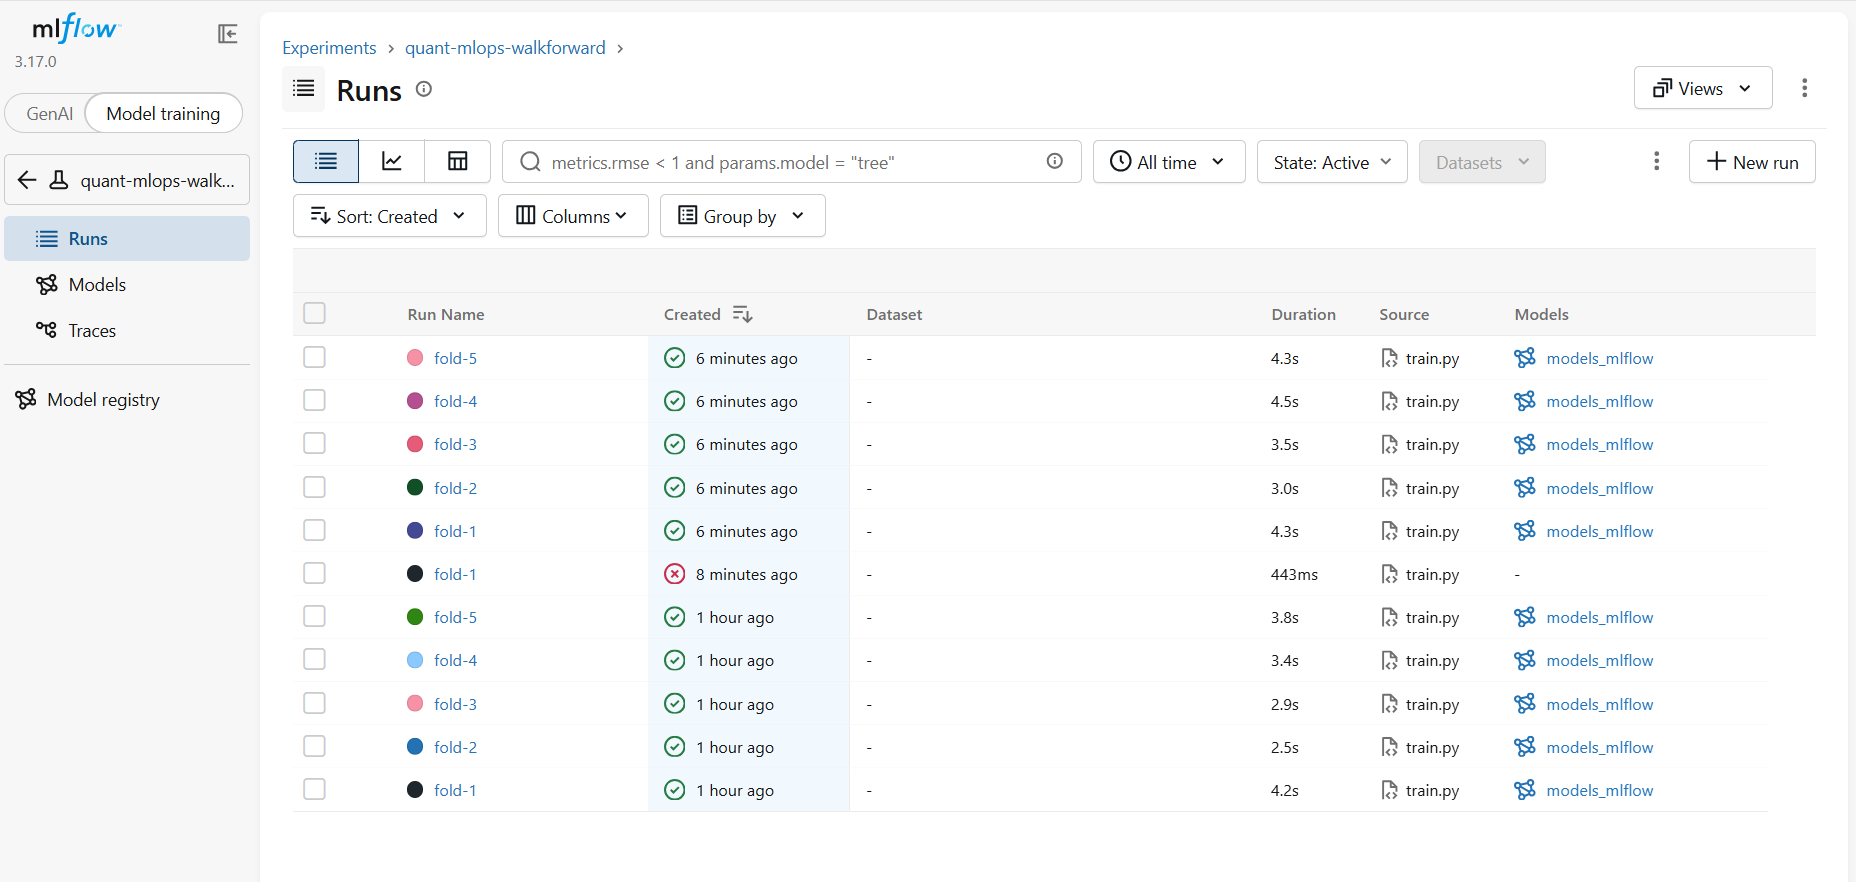
